In [1]:
import numpy as np
import matplotlib.pyplot as plt

def plot_environmental_heatmap(accuracies, temp_range, vdd_range, puf_name, attack_name):
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(accuracies, cmap="viridis", interpolation='nearest', origin='lower')
    
    cbar = ax.figure.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Model Accuracy", rotation=-90, va="bottom")

    ax.set_xticks(np.arange(len(vdd_range)))
    ax.set_yticks(np.arange(len(temp_range)))
    ax.set_xticklabels(vdd_range)
    ax.set_yticklabels(temp_range)
    ax.set_xlabel("Vdd (V)")
    ax.set_ylabel("Temperature (°C)")

    # Annotate with accuracy values
    #for r in range(len(temp_range)):
    #    for c in range(len(vdd_range)):
            #ax.text(c, r, f"{accuracies[r, c]:.3f}", ha="center", va="center", 
             #       color="w" if accuracies[r, c] < 0.8 else "black")

    ax.set_title(f"{attack_name} Accuracy vs. Environment\nTarget: {puf_name}")
    plt.tight_layout()
    plt.show()



Epoch 1/50


50/50 [==============================] - 2s 9ms/step - loss: 0.6589 - accuracy: 0.6105 - val_loss: 0.5472 - val_accuracy: 0.7380
Epoch 2/50
50/50 [==============================] - 0s 3ms/step - loss: 0.5066 - accuracy: 0.7828 - val_loss: 0.4377 - val_accuracy: 0.8560
Epoch 3/50
50/50 [==============================] - 0s 3ms/step - loss: 0.4213 - accuracy: 0.8583 - val_loss: 0.3743 - val_accuracy: 0.9080
Epoch 4/50
50/50 [==============================] - 0s 3ms/step - loss: 0.3674 - accuracy: 0.8922 - val_loss: 0.3322 - val_accuracy: 0.9220
Epoch 5/50
50/50 [==============================] - 0s 3ms/step - loss: 0.3294 - accuracy: 0.9109 - val_loss: 0.3020 - val_accuracy: 0.9320
Epoch 6/50
50/50 [==============================] - 0s 3ms/step - loss: 0.3008 - accuracy: 0.9242 - val_loss: 0.2787 - val_accuracy: 0.9380
Epoch 7/50
50/50 [==============================] - 0s 3ms/step - loss: 0.2783 - accuracy: 0.9332 - val_loss: 0.2595 - val_accuracy: 0.9440
Epoch 8/50
50/50

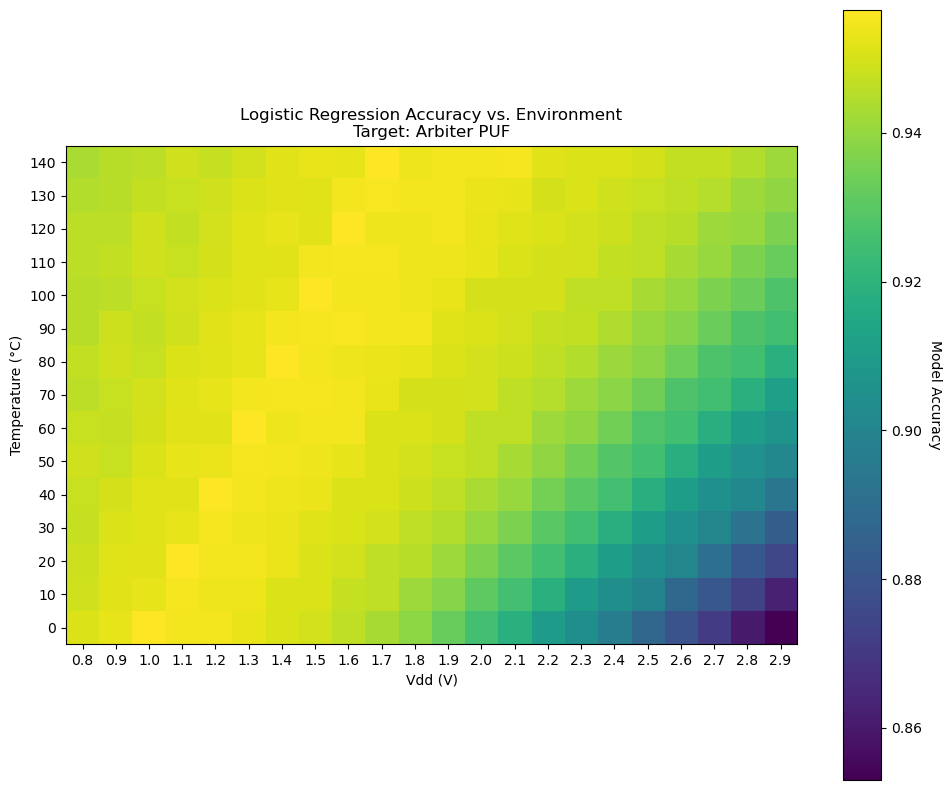

In [2]:
from pypuf.simulation import ArbiterPUF
from pypuf.io import ChallengeResponseSet
from pypuf.attack import LRAttack2021
from pypuf.metrics import similarity

# 1. Setup
n_bits, puf_seed = 64, 123
nom_temp, nom_vdd = 25.0, 1.2
n_train, n_test = 50000, 2000
temp_range = np.arange(0, 150, 10)
vdd_range = np.round(np.arange(0.8, 3.00, 0.1), 2)

# 2. Train at Nominal (Golden Point)
p_nom = ArbiterPUF(n=n_bits, seed=puf_seed, noisiness=0.05, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed= puf_seed)
# LR: (crps, seed, k, bs, lr, epochs) [cite: 39, 46]
model = LRAttack2021(train_crps, 42, 1, 1000, 1e-3, 50).fit() #[cite: 58]
model.temperature, model.vdd = nom_temp, nom_vdd


# 3. Environmental Sweep
acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = ArbiterPUF(n=n_bits, seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0] #[cite: 358]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Arbiter PUF", "Logistic Regression")

Epoch 1/50
99/99 [==============================] - 2s 8ms/step - loss: 0.6932 - accuracy: 0.4987 - val_loss: 0.6934 - val_accuracy: 0.5000
Epoch 2/50
99/99 [==============================] - 0s 4ms/step - loss: 0.6929 - accuracy: 0.5041 - val_loss: 0.6933 - val_accuracy: 0.4940
Epoch 3/50
99/99 [==============================] - 0s 5ms/step - loss: 0.6927 - accuracy: 0.5074 - val_loss: 0.6932 - val_accuracy: 0.4920
Epoch 4/50
99/99 [==============================] - 0s 5ms/step - loss: 0.6924 - accuracy: 0.5080 - val_loss: 0.6932 - val_accuracy: 0.4930
Epoch 5/50
99/99 [==============================] - 0s 5ms/step - loss: 0.6921 - accuracy: 0.5111 - val_loss: 0.6932 - val_accuracy: 0.4910
Epoch 6/50
99/99 [==============================] - 0s 5ms/step - loss: 0.6917 - accuracy: 0.5146 - val_loss: 0.6929 - val_accuracy: 0.4960
Epoch 7/50
99/99 [==============================] - 0s 4ms/step - loss: 0.6908 - accuracy: 0.5208 - val_loss: 0.6916 - val_accuracy: 0.5390
Epoch 8/50
99/99 [==

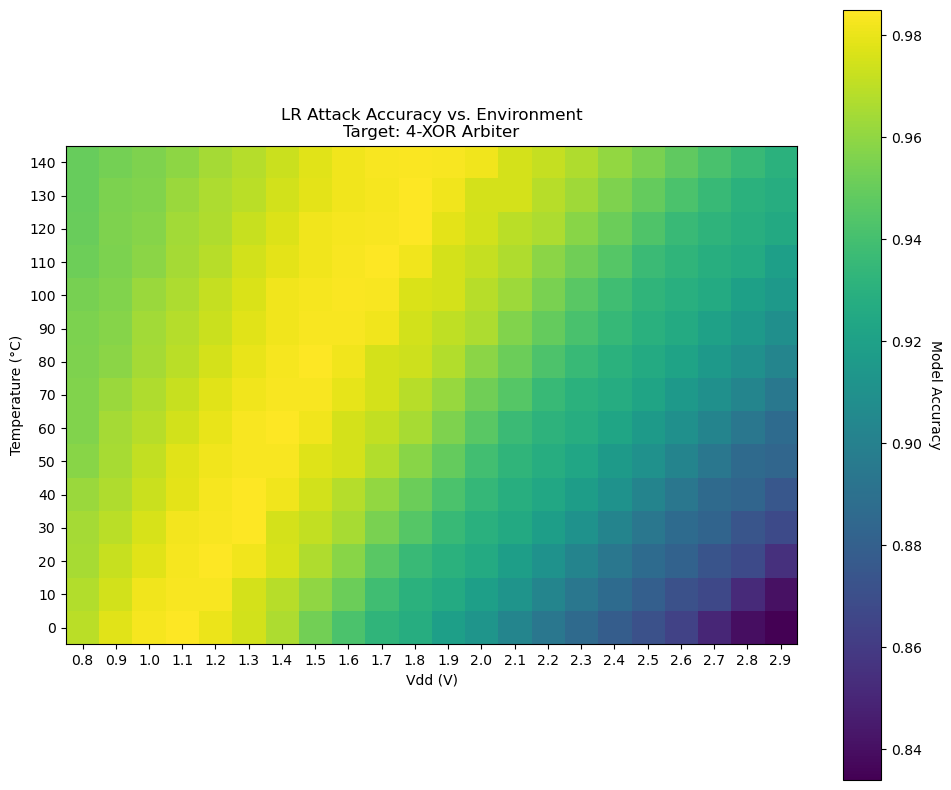

In [4]:
from pypuf.simulation import XORArbiterPUF
from pypuf.attack import LRAttack2021

k = 4
p_nom = XORArbiterPUF(n=n_bits, k=k, seed=puf_seed, noisiness=0.05, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=100000, seed=puf_seed) 

# LR Attack: (crps, seed, k, bs, lr, epochs)
model = LRAttack2021(train_crps, seed=42, k=k, bs=1000, lr=1e-3, epochs=50).fit()
model.temperature, model.vdd = nom_temp, nom_vdd

acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = XORArbiterPUF(n=n_bits, k=k, seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, f"{k}-XOR Arbiter", "LR Attack")

Epoch 1/50
50/50 [==============================] - 2s 12ms/step - loss: 0.7252 - accuracy: 0.5307 - val_loss: 0.6509 - val_accuracy: 0.6200
Epoch 2/50
50/50 [==============================] - 0s 4ms/step - loss: 0.6166 - accuracy: 0.6650 - val_loss: 0.5746 - val_accuracy: 0.7380
Epoch 3/50
50/50 [==============================] - 0s 5ms/step - loss: 0.5541 - accuracy: 0.7417 - val_loss: 0.5267 - val_accuracy: 0.7840
Epoch 4/50
50/50 [==============================] - 0s 5ms/step - loss: 0.5118 - accuracy: 0.7808 - val_loss: 0.4939 - val_accuracy: 0.8000
Epoch 5/50
50/50 [==============================] - 0s 5ms/step - loss: 0.4807 - accuracy: 0.8030 - val_loss: 0.4683 - val_accuracy: 0.8160
Epoch 6/50
50/50 [==============================] - 0s 5ms/step - loss: 0.4566 - accuracy: 0.8161 - val_loss: 0.4489 - val_accuracy: 0.8140
Epoch 7/50
50/50 [==============================] - 0s 4ms/step - loss: 0.4373 - accuracy: 0.8237 - val_loss: 0.4325 - val_accuracy: 0.8340
Epoch 8/50
50/50 [=

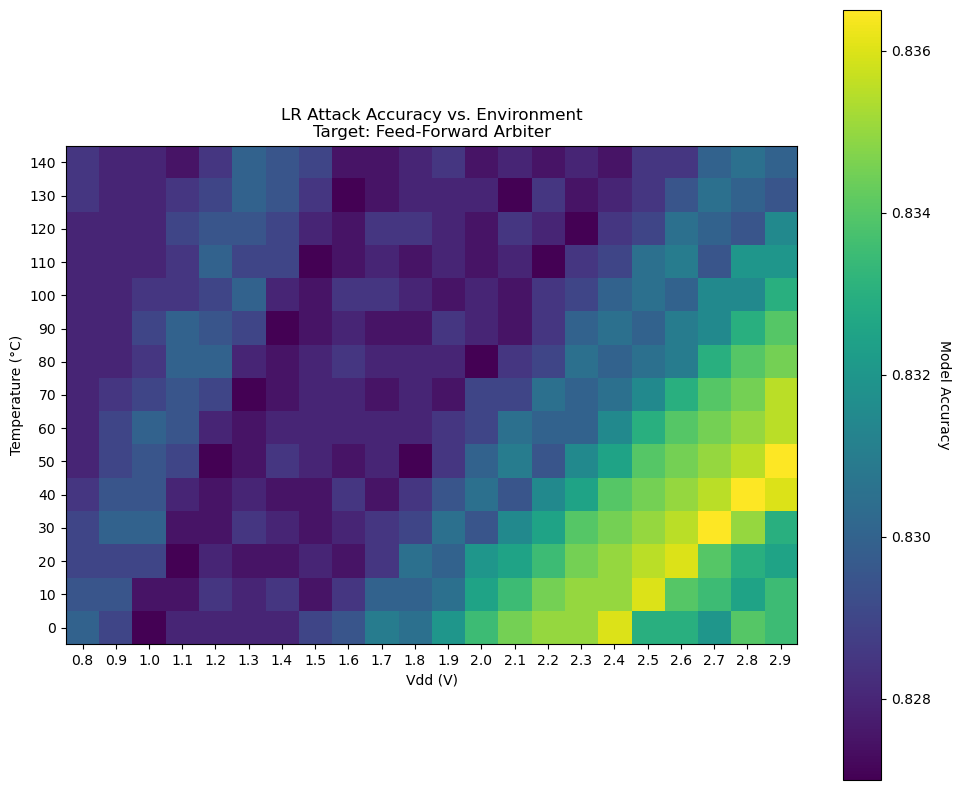

In [5]:
from pypuf.simulation import FeedForwardArbiterPUF

# Define FF bit indices: [(trigger_index, target_index), ...]
ff_config = [(10, 20), (30, 40)]
p_nom = FeedForwardArbiterPUF(n=n_bits, ff=ff_config, seed=puf_seed, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed=puf_seed)

# FF Arbiter is modeled as k=1 for basic LR, though accuracy may vary due to internal dependencies
model = LRAttack2021(train_crps, seed=42, k=1, bs=1000, lr=1e-3, epochs=50).fit()
model.temperature, model.vdd = nom_temp, nom_vdd

acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = FeedForwardArbiterPUF(n=n_bits, ff=ff_config, seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Feed-Forward Arbiter", "LR Attack")

Epoch 1/50
50/50 [==============================] - 1s 6ms/step - loss: 0.7206 - accuracy: 0.5017 - val_loss: 0.7071 - val_accuracy: 0.4980
Epoch 2/50
50/50 [==============================] - 0s 3ms/step - loss: 0.6973 - accuracy: 0.5027 - val_loss: 0.6956 - val_accuracy: 0.5040
Epoch 3/50
50/50 [==============================] - 0s 3ms/step - loss: 0.6936 - accuracy: 0.5054 - val_loss: 0.6938 - val_accuracy: 0.5080
Epoch 4/50
50/50 [==============================] - 0s 4ms/step - loss: 0.6931 - accuracy: 0.5085 - val_loss: 0.6947 - val_accuracy: 0.4920
Epoch 5/50
50/50 [==============================] - 0s 4ms/step - loss: 0.6931 - accuracy: 0.5094 - val_loss: 0.6936 - val_accuracy: 0.5040
Epoch 6/50
50/50 [==============================] - 0s 4ms/step - loss: 0.6931 - accuracy: 0.5066 - val_loss: 0.6932 - val_accuracy: 0.5140
Epoch 7/50
50/50 [==============================] - 0s 4ms/step - loss: 0.6931 - accuracy: 0.5093 - val_loss: 0.6936 - val_accuracy: 0.5320
Epoch 8/50
50/50 [==

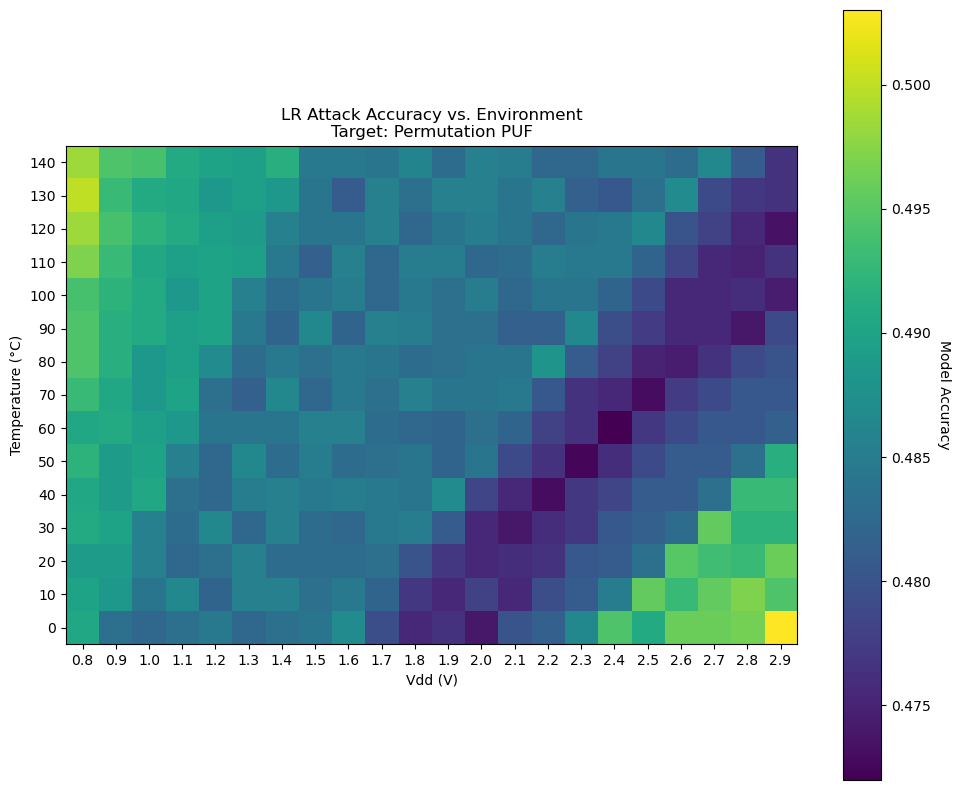

In [6]:
from pypuf.simulation import PermutationPUF

# 1. Setup Data Generation
p_nom = PermutationPUF(n=n_bits, seed=puf_seed, temperature=nom_temp, vdd=nom_vdd, k=8)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed=puf_seed)

# 2. Run LR Attack
model = LRAttack2021(train_crps, seed=42, k=1, bs=1000, lr=1e-3, epochs=50).fit()
model.temperature, model.vdd = nom_temp, nom_vdd

# 3. Environmental Sweep
acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = PermutationPUF(n=n_bits, seed=puf_seed, temperature=t, vdd=v, k=8)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Permutation PUF", "LR Attack")

Epoch 1/50
297/297 [==============================] - 3s 4ms/step - loss: 0.6863 - accuracy: 0.5317 - val_loss: 0.6610 - val_accuracy: 0.6050
Epoch 2/50
297/297 [==============================] - 1s 2ms/step - loss: 0.6205 - accuracy: 0.6564 - val_loss: 0.6117 - val_accuracy: 0.6537
Epoch 3/50
297/297 [==============================] - 1s 2ms/step - loss: 0.5996 - accuracy: 0.6682 - val_loss: 0.6011 - val_accuracy: 0.6577
Epoch 4/50
297/297 [==============================] - 1s 2ms/step - loss: 0.5928 - accuracy: 0.6710 - val_loss: 0.5985 - val_accuracy: 0.6623
Epoch 5/50
297/297 [==============================] - 1s 3ms/step - loss: 0.5906 - accuracy: 0.6709 - val_loss: 0.5979 - val_accuracy: 0.6630
Epoch 6/50
297/297 [==============================] - 1s 3ms/step - loss: 0.5898 - accuracy: 0.6714 - val_loss: 0.5973 - val_accuracy: 0.6640
Epoch 7/50
297/297 [==============================] - 1s 3ms/step - loss: 0.5894 - accuracy: 0.6715 - val_loss: 0.5967 - val_accuracy: 0.6667
Epoch 

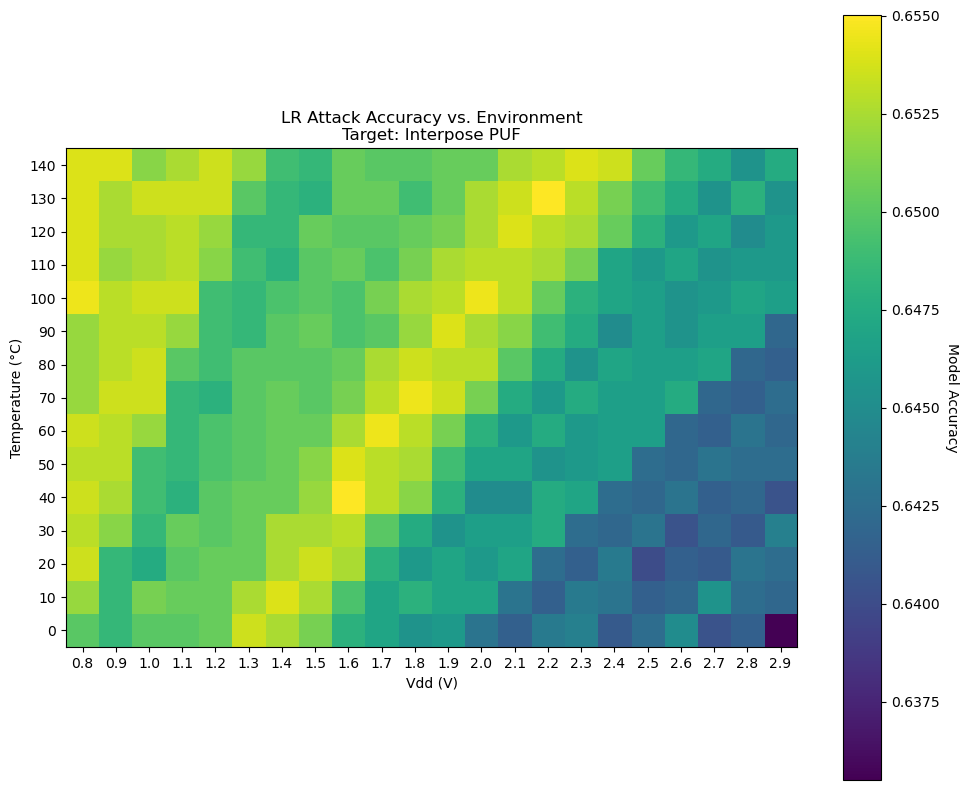

In [7]:
from pypuf.simulation import InterposePUF

# k_up and k_down represent the top and bottom Arbiter chains
k_up, k_down = 2, 2
p_nom = InterposePUF(n=n_bits, k_up=k_up, k_down=k_down, seed=puf_seed, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=300000, seed=puf_seed) 

# Logistic Regression treats the combined Interpose structure as a k-XOR problem (k_up + k_down)
model = LRAttack2021(train_crps, seed=42, k=k_up + k_down, bs=1000, lr=1e-3, epochs=50).fit()
model.temperature, model.vdd = nom_temp, nom_vdd

acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = InterposePUF(n=n_bits, k_up=k_up, k_down=k_down, seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Interpose PUF", "LR Attack")